# EDA: crescimento e risco do crédito nacional (SCR.data, 2024–2025)

**Pergunta orientadora:** onde o crédito brasileiro está crescendo entre 2024 e 2025, e esse crescimento vem acompanhado de mais risco?

Fonte: Banco Central do Brasil, SCR.data (licença ODbL). Os dados foram preparados por `src/extract.py` e `src/transform.py`. Os indicadores vêm de `src/analysis.py` (as mesmas funções usadas pelo app).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # permite importar src/

import pandas as pd
import matplotlib.pyplot as plt
from src import analysis, config

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
fato = pd.read_parquet(config.DIR_PROCESSED / 'fato_credito.parquet')
qualidade = pd.read_parquet(config.DIR_PROCESSED / 'qualidade_mensal.parquet')
SAIDA = config.DIR_OUTPUTS
FONTE = 'Fonte: Banco Central do Brasil, SCR.data'
fato.shape

(319485, 16)

## 1. Qualidade dos dados

Antes de analisar, verificamos linhas, nulos, duplicadas e combinações suprimidas por sigilo (`numero_de_operacoes = -1`) em cada arquivo mensal bruto.

In [2]:
qualidade

,ano_mes,linhas,nulos,duplicadas,combinacoes_suprimidas
0,2024-01,311692,0,0,87360
1,2024-02,312030,0,0,87222
2,2024-03,312636,0,0,87172
3,2024-04,312358,0,0,86484
4,2024-05,313841,0,0,86453
5,2024-06,306976,0,0,83646
6,2024-07,309604,0,0,84984
7,2024-08,310263,0,0,84889
8,2024-09,309037,0,0,84224
9,2024-10,308777,0,0,83677


In [3]:
print('Tipos das colunas:')
print(fato.dtypes)
print('\nPercentual de combinações suprimidas por mês:')
print((qualidade['combinacoes_suprimidas'] / qualidade['linhas'] * 100).describe())
print('\nCombinações no fato por mês (queda a partir de jul/2025):')
print(fato.groupby('ano_mes').size().loc['2025-05':'2025-08'])

Tipos das colunas:
ano_mes                           str
uf                           category
regiao                       category
cliente                      category
segmento                     category
modalidade                   category
grupo_credito                category
porte                        category
numero_operacoes                int64
combinacoes_suprimidas          int64
carteira_a_vencer             float64
vencido_de_15_ate_90_dias     float64
carteira_vencida              float64
carteira_ativa                float64
carteira_inadimplencia        float64
ativo_problematico            float64
dtype: object

Percentual de combinações suprimidas por mês:
count   24.00
mean    26.88
std      0.66
min     25.95
25%     26.37
50%     26.77
75%     27.38
max     28.03
dtype: float64

Combinações no fato por mês (queda a partir de jul/2025):
ano_mes
2025-05    13576
2025-06    13608
2025-07    12773
2025-08    12824
dtype: int64


In [4]:
# A queda de combinações em jul/2025 muda os totais? Comparamos a carteira por segmento antes e depois.
(fato.groupby(['ano_mes', 'segmento'], observed=True)['carteira_ativa'].sum().unstack() / 1e9).loc['2025-05':'2025-08'].T.round(1)

ano_mes,2025-05,2025-06,2025-07,2025-08
segmento,,,,
Arrendamento,18.50,18.60,18.90,19.40
Banco,"5,567.90","5,605.90","5,605.30","5,655.40"
Cooperativa,475.10,478.70,482.90,490.00
Desenvolvimento/Fomento,382.40,382.50,387.10,387.20
Financeira,328.80,337.10,343.60,348.90
Fintech,5.80,5.90,6.10,6.60
Instituição de pagamento,86.90,88.50,90.90,95.20
Outros,6.10,6.10,6.10,6.10


**Leitura:** nenhuma categoria mudou de jun para jul/2025 e os saldos seguem contínuos. A queda de combinações vem de cruzamentos pequenos que deixaram de aparecer e não altera os totais.

## 2. Visão geral: evolução mensal

In [5]:
total = analysis.serie_mensal(fato)
por_cliente = analysis.serie_mensal(fato, por='cliente')
k = analysis.kpis(fato, '2024-12', '2025-12')
k

{'carteira_base': 6688616692283.4,
 'carteira_ref': 7444320851724.66,
 'crescimento_pct': 11.298362489707463,
 'inadimplencia_base_pct': 2.9910200483383216,
 'inadimplencia_ref_pct': 4.104543459938466,
 'participacao_fintech_pct': 0.09619472550838494}

In [6]:
total.set_index('ano_mes')[['carteira_ativa', 'taxa_inadimplencia', 'taxa_ativo_problematico']].assign(carteira_ativa=lambda d: d['carteira_ativa'] / 1e12).rename(columns={'carteira_ativa': 'carteira_R$_tri'})

,carteira_R$_tri,taxa_inadimplencia,taxa_ativo_problematico
ano_mes,,,
2024-01,5.96,3.18,7.25
2024-02,5.98,3.19,7.26
2024-03,6.06,3.14,7.21
2024-04,6.09,3.17,7.22
2024-05,6.13,3.22,7.23
2024-06,6.24,3.11,7.05
2024-07,6.27,3.13,6.98
2024-08,6.34,3.16,6.85
2024-09,6.43,3.14,6.74


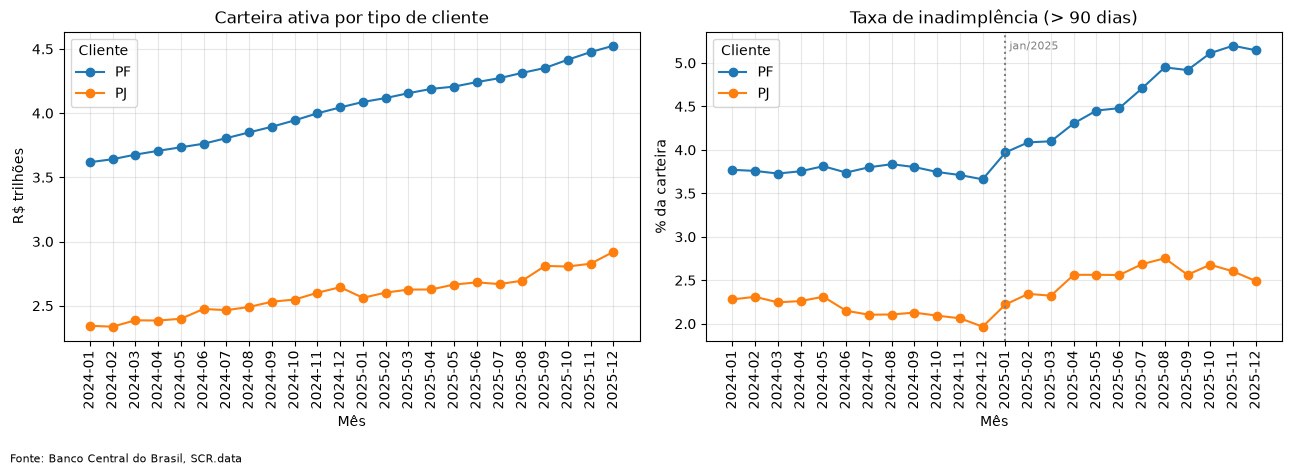

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for cliente, g in por_cliente.groupby('cliente', observed=True):
    ax1.plot(g['ano_mes'], g['carteira_ativa'] / 1e12, marker='o', label=cliente)
    ax2.plot(g['ano_mes'], g['taxa_inadimplencia'], marker='o', label=cliente)
ax2.axvline('2025-01', ls=':', c='gray')
ax2.text('2025-01', ax2.get_ylim()[1] * 0.98, ' jan/2025', va='top', fontsize=8, color='gray')
ax1.set(title='Carteira ativa por tipo de cliente', xlabel='Mês', ylabel='R$ trilhões')
ax2.set(title='Taxa de inadimplência (> 90 dias)', xlabel='Mês', ylabel='% da carteira')
for ax in (ax1, ax2):
    ax.tick_params(axis='x', rotation=90)
    ax.legend(title='Cliente')
    ax.grid(alpha=.3)
fig.text(0.01, -0.04, FONTE, fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA / '01_evolucao.png', dpi=150, bbox_inches='tight')

## 3. Estatística descritiva: inadimplência mensal por grupo

Para cada grupo, resumimos os 24 meses de taxa de inadimplência com centro (média, mediana), dispersão (desvio-padrão, quartis) e extremos.

In [8]:
analysis.descritivas_por_grupo(fato, 'cliente')

,media,mediana,desvio_padrao,q1,q3,minimo,maximo,n_meses
cliente,,,,,,,,
PF,4.19,3.90,0.54,3.76,4.54,3.66,5.20,24
PJ,2.35,2.31,0.23,2.14,2.56,1.97,2.75,24


In [9]:
analysis.descritivas_por_grupo(fato, 'segmento')

,media,mediana,desvio_padrao,q1,q3,minimo,maximo,n_meses
segmento,,,,,,,,
Fintech,11.19,10.90,2.34,9.20,12.44,8.03,16.47,24
Financeira,10.45,9.75,1.47,9.24,12.34,8.82,12.60,24
Cooperativa,3.76,3.32,0.80,3.08,4.68,2.89,5.07,24
Banco,3.32,3.19,0.33,3.06,3.51,2.90,3.94,24
Outros,1.51,1.53,0.23,1.32,1.57,1.16,2.02,24
Instituição de pagamento,0.66,0.63,0.27,0.48,0.72,0.33,1.20,24
Arrendamento,0.56,0.52,0.19,0.47,0.64,0.22,1.03,24
Desenvolvimento/Fomento,0.23,0.22,0.06,0.19,0.26,0.15,0.35,24


In [10]:
analysis.descritivas_por_grupo(fato, 'modalidade')

,media,mediana,desvio_padrao,q1,q3,minimo,maximo,n_meses
modalidade,,,,,,,,
Adiantamentos a depositantes,54.93,55.24,5.38,50.31,58.05,45.44,66.80,24
Empréstimos,6.95,6.74,0.57,6.50,7.51,6.28,7.93,24
Direitos creditórios descontados,3.38,3.42,0.30,3.16,3.59,2.91,4.10,24
Financiamentos,2.40,2.22,0.32,2.15,2.72,2.00,2.89,24
Financiamentos rurais (ex-financiamentos rurais e agroindustriais),2.42,2.08,1.40,1.24,2.92,0.89,5.28,24
Financiamentos imobiliários,1.27,1.24,0.13,1.18,1.30,1.06,1.56,24
Outros créditos,0.67,0.70,0.24,0.44,0.84,0.36,1.14,24
Operações de arrendamento,0.60,0.58,0.17,0.50,0.69,0.30,1.08,24
Financiamentos à exportação,0.59,0.47,0.27,0.36,0.84,0.20,1.04,24


In [11]:
desc_uf = analysis.descritivas_por_grupo(fato, 'uf')
desc_uf

,media,mediana,desvio_padrao,q1,q3,minimo,maximo,n_meses
uf,,,,,,,,
PE,4.79,4.87,0.24,4.62,4.98,4.22,5.09,24
MA,5.27,4.64,1.13,4.41,5.84,4.31,7.69,24
AL,4.59,4.56,0.35,4.27,4.92,3.96,5.13,24
RN,4.63,4.55,0.32,4.40,4.92,4.09,5.21,24
PB,4.53,4.41,0.44,4.26,4.66,3.87,5.54,24
SE,4.61,4.41,0.42,4.24,5.06,4.11,5.23,24
RR,4.57,4.33,0.62,4.06,5.15,3.84,5.64,24
AM,4.37,4.30,0.42,4.04,4.61,3.63,5.11,24
BA,4.35,4.22,0.31,4.16,4.53,3.71,4.93,24


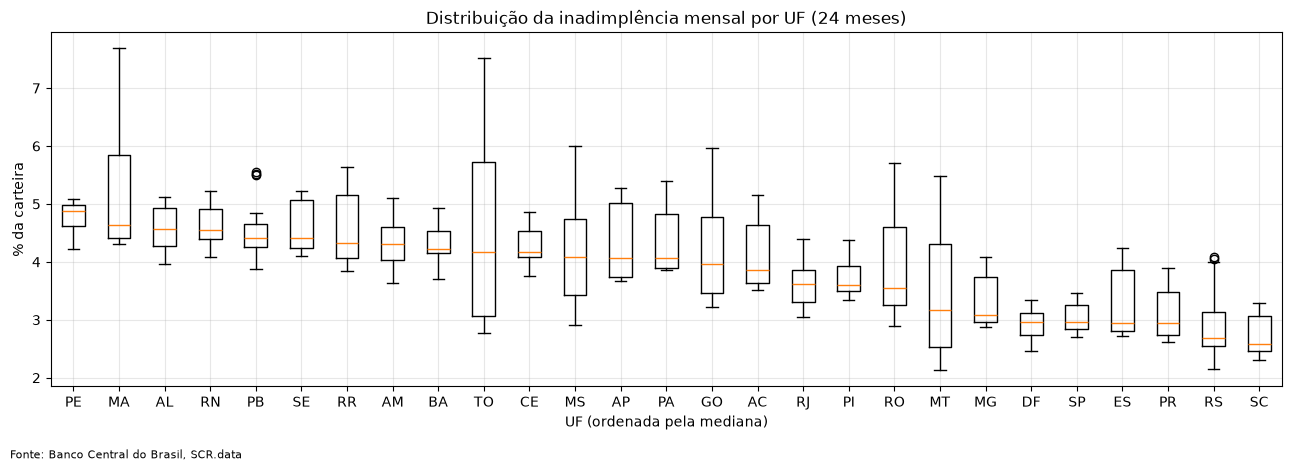

In [12]:
mensal_uf = analysis.serie_mensal(fato, por='uf')
ordem = desc_uf.index.astype(str).tolist()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.boxplot([mensal_uf.loc[mensal_uf['uf'] == uf, 'taxa_inadimplencia'] for uf in ordem], tick_labels=ordem)
ax.set(title='Distribuição da inadimplência mensal por UF (24 meses)', xlabel='UF (ordenada pela mediana)', ylabel='% da carteira')
ax.grid(alpha=.3)
fig.text(0.01, -0.03, FONTE, fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA / '02_boxplot_uf.png', dpi=150, bbox_inches='tight')

## 4. Crescimento × risco: correlação de Spearman

Unidade de análise: cada combinação **tipo de instituição × modalidade × PF/PJ** com carteira de pelo menos R$ 1 bi em dez/2024. Comparamos o crescimento da carteira (dez/24 → dez/25) com a variação da inadimplência em pontos percentuais.

In [13]:
cxr = analysis.crescimento_x_risco(fato, '2024-12', '2025-12')
corr = analysis.correlacao_spearman(cxr, 'crescimento_pct', 'variacao_inadimplencia_pp')
print(corr)
print(analysis.interpretar_spearman(corr['rho'], corr['p_valor']))
cxr.sort_values('carteira_ativa_ref', ascending=False).head(15)

{'rho': 0.11976284584980236, 'p_valor': 0.4332675312276441, 'n': 45}
A correlação (ρ = 0.12) não é estatisticamente significativa (p = 0.433): não há evidência de que crescer mais ande junto com mais risco neste recorte.


,segmento,modalidade,cliente,carteira_ativa_base,carteira_ativa_ref,crescimento_pct,inadimplencia_base_pct,inadimplencia_ref_pct,variacao_inadimplencia_pp
8,Banco,Financiamentos imobiliários,PF,"1,167,500,438,091.54","1,311,871,192,950.97",12.37,1.10,1.09,-0.00
2,Banco,Empréstimos,PF,"1,098,674,775,822.07","1,196,937,632,338.12",8.94,6.84,8.07,1.23
3,Banco,Empréstimos,PJ,"781,381,641,709.07","895,345,820,588.17",14.58,4.33,4.68,0.34
10,Banco,Financiamentos rurais (ex-financiamentos rurai...,PF,"543,971,990,114.37","562,999,149,095.01",3.50,2.50,6.98,4.48
5,Banco,Financiamentos,PJ,"376,307,363,087.18","420,925,196,746.00",11.86,1.35,1.91,0.57
16,Banco,Outros créditos,PF,"341,400,094,560.51","383,261,954,711.96",12.26,0.05,0.05,0.01
30,Desenvolvimento/Fomento,Financiamentos,PJ,"344,329,912,212.09","365,770,200,125.92",6.23,0.08,0.23,0.14
4,Banco,Financiamentos,PF,"252,050,361,594.52","305,570,187,897.93",21.23,4.85,6.74,1.89
13,Banco,Financiamentos à exportação,PJ,"284,576,752,509.72","292,476,255,494.86",2.78,0.35,0.57,0.22
17,Banco,Outros créditos,PJ,"226,507,637,185.76","225,330,413,587.20",-0.52,0.72,1.50,0.78


In [14]:
# Sensibilidade: o resultado muda se trocarmos o corte mínimo de carteira?
pd.DataFrame([{'carteira_minima_R$_bi': m, **analysis.correlacao_spearman(
    analysis.crescimento_x_risco(fato, '2024-12', '2025-12', carteira_minima=m * 1e9),
    'crescimento_pct', 'variacao_inadimplencia_pp')} for m in [0.1, 0.5, 1, 5, 10]])

,carteira_minima_R$_bi,rho,p_valor,n
0,0.10,0.16,0.20,64
1,0.50,0.15,0.28,51
2,1.00,0.12,0.43,45
3,5.00,-0.03,0.85,34
4,10.00,0.05,0.80,31


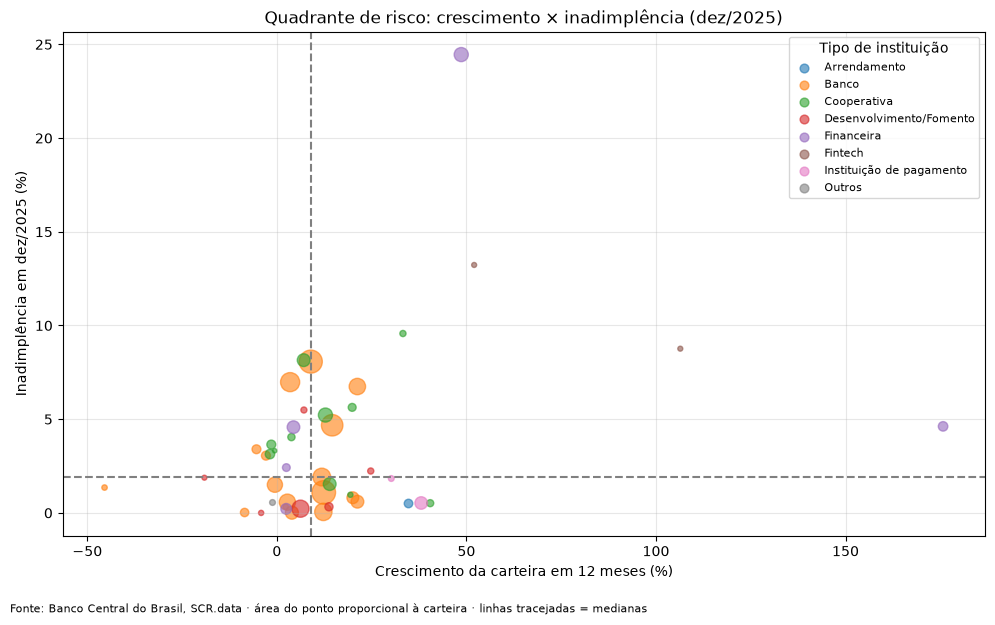

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
for seg, g in cxr.groupby('segmento', observed=True):
    # raiz quadrada no tamanho: a área do ponto fica proporcional à carteira sem esconder os segmentos pequenos
    ax.scatter(g['crescimento_pct'], g['inadimplencia_ref_pct'], s=8 * (g['carteira_ativa_ref'] / 1e9) ** 0.5, alpha=.6, label=seg)
ax.axvline(cxr['crescimento_pct'].median(), ls='--', c='gray')
ax.axhline(cxr['inadimplencia_ref_pct'].median(), ls='--', c='gray')
ax.set(title='Quadrante de risco: crescimento × inadimplência (dez/2025)', xlabel='Crescimento da carteira em 12 meses (%)', ylabel='Inadimplência em dez/2025 (%)')
legenda = ax.legend(title='Tipo de instituição', fontsize=8)
for marcador in legenda.legend_handles:
    marcador.set_sizes([40])
ax.grid(alpha=.3)
fig.text(0.01, -0.03, FONTE + ' · área do ponto proporcional à carteira · linhas tracejadas = medianas', fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA / '03_quadrante.png', dpi=150, bbox_inches='tight')

## 5. Tendência temporal da inadimplência

Regressão linear simples da taxa mensal. A inclinação é a variação média por mês, em p.p. Ressalva: 24 pontos é uma série curta.

Como o gráfico da seção 2 sugere uma mudança de comportamento em jan/2025, calculamos a tendência nos 24 meses **e também separadamente em cada ano**.

In [16]:
linhas = []
for nome, serie in [('Total', total)] + [(c, g) for c, g in por_cliente.groupby('cliente', observed=True)]:
    for periodo, filtro in [('2024–2025', slice(None)), ('2024', serie['ano_mes'].str.startswith('2024')), ('2025', serie['ano_mes'].str.startswith('2025'))]:
        linhas.append({'grupo': nome, 'periodo': periodo, **analysis.tendencia_linear(serie.loc[filtro, 'taxa_inadimplencia'])})
tendencias = pd.DataFrame(linhas)
tendencias

,grupo,periodo,inclinacao,ic95_inferior,ic95_superior,r2,p_valor,n
0,Total,2024–2025,0.05,0.04,0.06,0.77,0.00,24
1,Total,2024,-0.01,-0.02,-0.01,0.62,0.00,12
2,Total,2025,0.09,0.07,0.10,0.92,0.00,12
3,PF,2024–2025,0.07,0.05,0.08,0.81,0.00,24
4,PF,2024,-0.00,-0.01,0.01,0.09,0.35,12
5,PF,2025,0.12,0.11,0.14,0.97,0.00,12
6,PJ,2024–2025,0.02,0.01,0.03,0.50,0.00,24
7,PJ,2024,-0.03,-0.04,-0.02,0.84,0.00,12
8,PJ,2025,0.03,0.01,0.05,0.45,0.02,12


In [17]:
# Tamanho do salto na virada do ano, comparado com as variações mensais típicas de 2024
t = total.set_index('ano_mes')
salto = t.loc['2025-01', 'taxa_inadimplencia'] - t.loc['2024-12', 'taxa_inadimplencia']
var_2024 = t['taxa_inadimplencia'].diff().loc['2024-02':'2024-12']
print(f'Salto dez/24 -> jan/25: {salto:+.2f} p.p.')
print(f'Variação mensal em 2024: média {var_2024.mean():+.3f} p.p., maior alta {var_2024.max():+.2f} p.p.')
salto_ap = t.loc['2025-01', 'taxa_ativo_problematico'] - t.loc['2024-12', 'taxa_ativo_problematico']
print(f'Ativo problemático no mesmo mês: {salto_ap:+.2f} p.p.')

Salto dez/24 -> jan/25: +0.31 p.p.
Variação mensal em 2024: média -0.018 p.p., maior alta +0.06 p.p.
Ativo problemático no mesmo mês: +0.51 p.p.


## 6. Quem empresta: participação de mercado e concentração (HHI)

In [18]:
part, hhi = analysis.participacao_e_hhi(fato, '2025-12')
print(f'HHI = {hhi:,.0f}: {analysis.classificar_hhi(hhi)}')
seg = analysis.crescimento_x_risco(fato, '2024-12', '2025-12', chaves=('segmento',), carteira_minima=0)
part.merge(seg[['segmento', 'crescimento_pct', 'inadimplencia_base_pct', 'inadimplencia_ref_pct', 'variacao_inadimplencia_pp']], on='segmento')

HHI = 6,594: alta concentração (HHI > 2.500)


,segmento,carteira_ativa,participacao_pct,crescimento_pct,inadimplencia_base_pct,inadimplencia_ref_pct,variacao_inadimplencia_pp
0,Banco,"5,996,438,213,687.77",80.55,10.13,2.90,3.84,0.93
1,Cooperativa,"513,379,071,255.25",6.90,12.08,3.08,4.72,1.64
2,Desenvolvimento/Fomento,"403,393,911,007.14",5.42,6.55,0.15,0.35,0.20
3,Financeira,"384,929,339,170.12",5.17,28.21,8.82,12.50,3.68
4,Instituição de pagamento,"109,588,408,585.02",1.47,37.63,0.38,0.64,0.26
5,Arrendamento,"23,289,934,417.74",0.31,37.13,0.49,0.53,0.04
6,Fintech,"7,161,044,009.28",0.10,65.26,8.96,10.85,1.89
7,Outros,"6,140,929,592.34",0.08,2.85,1.52,1.32,-0.20


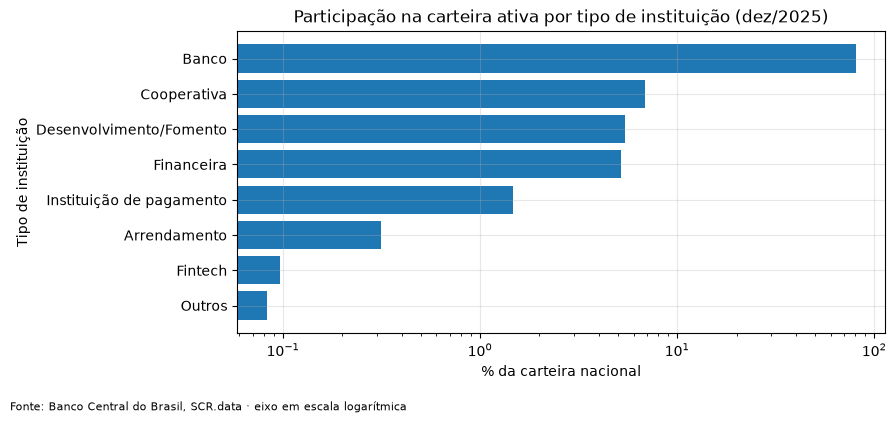

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(part['segmento'].astype(str), part['participacao_pct'])
ax.invert_yaxis()
ax.set(title='Participação na carteira ativa por tipo de instituição (dez/2025)', xlabel='% da carteira nacional', ylabel='Tipo de instituição')
ax.set_xscale('log')
ax.grid(alpha=.3)
fig.text(0.01, -0.04, FONTE + ' · eixo em escala logarítmica', fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA / '04_participacao.png', dpi=150, bbox_inches='tight')

In [20]:
# Livre x direcionado
analysis.crescimento_x_risco(fato, '2024-12', '2025-12', chaves=('grupo_credito',), carteira_minima=0)

,grupo_credito,carteira_ativa_base,carteira_ativa_ref,crescimento_pct,inadimplencia_base_pct,inadimplencia_ref_pct,variacao_inadimplencia_pp
0,Direcionado,"2,421,166,253,876.78","2,665,452,077,092.98",10.09,1.06,1.70,0.64
1,Livre,"4,267,450,438,406.62","4,778,868,774,631.68",11.98,4.09,5.45,1.36


In [21]:
# Quantos segmentos estão no quadrante 'cresceu acima da mediana e tem inadimplência acima da mediana'?
q = cxr[(cxr['crescimento_pct'] > cxr['crescimento_pct'].median()) & (cxr['inadimplencia_ref_pct'] > cxr['inadimplencia_ref_pct'].median())]
print(f'{len(q)} de {len(cxr)} segmentos, {q.carteira_ativa_ref.sum() / cxr.carteira_ativa_ref.sum() * 100:.1f}% da carteira')
q.sort_values('carteira_ativa_ref', ascending=False)

10 de 45 segmentos, 21.6% da carteira


,segmento,modalidade,cliente,carteira_ativa_base,carteira_ativa_ref,crescimento_pct,inadimplencia_base_pct,inadimplencia_ref_pct,variacao_inadimplencia_pp
3,Banco,Empréstimos,PJ,"781,381,641,709.07","895,345,820,588.17",14.58,4.33,4.68,0.34
4,Banco,Financiamentos,PF,"252,050,361,594.52","305,570,187,897.93",21.23,4.85,6.74,1.89
35,Financeira,Empréstimos,PF,"113,012,689,806.67","167,972,565,669.79",48.63,19.30,24.45,5.16
21,Cooperativa,Empréstimos,PJ,"148,479,844,728.84","167,503,331,756.53",12.81,3.75,5.22,1.47
36,Financeira,Empréstimos,PJ,"12,542,969,723.55","34,583,453,288.61",175.72,3.75,4.62,0.87
27,Cooperativa,Outros créditos,PF,"14,065,531,065.88","16,859,486,665.69",19.86,3.18,5.63,2.45
28,Cooperativa,Outros créditos,PJ,"4,749,539,629.36","6,328,987,920.58",33.25,6.61,9.57,2.96
32,Desenvolvimento/Fomento,Financiamentos rurais (ex-financiamentos rurai...,PF,"4,997,760,725.32","6,235,288,606.64",24.76,0.97,2.24,1.26
41,Fintech,Empréstimos,PJ,"1,765,349,847.55","2,683,985,958.53",52.04,6.93,13.23,6.30
40,Fintech,Empréstimos,PF,"1,295,197,616.04","2,673,421,771.73",106.41,17.00,8.76,-8.23


## 7. Conclusões

Resposta à pergunta: **o crédito cresceu e o risco também subiu, mas o aumento do risco foi amplo e não se concentrou nos segmentos que mais cresceram.**

### Observações (o que os dados mostram)
1. A carteira ativa cresceu **11,30%** em 12 meses, de R$ 6,69 tri (dez/2024) para R$ 7,44 tri (dez/2025) (seção 2). PF cresceu 11,89% e PJ, 10,40%.
2. A inadimplência total subiu de **2,99% para 4,10%** (+1,11 p.p.). Em PF foi de 3,66% para 5,15% (+1,48 p.p.); em PJ, de 1,97% para 2,49% (+0,52 p.p.).
3. Há dois regimes. Em 2024, a tendência da inadimplência total foi levemente **negativa** (-0,01 p.p./mês, IC 95% de -0,02 a -0,01). Em 2025, foi **positiva** (+0,09 p.p./mês, IC 95% de +0,07 a +0,10, R² = 0,92), puxada por PF (+0,12 p.p./mês, R² = 0,97) (seção 5).
4. A virada dez/2024 → jan/2025 teve um salto de **+0,31 p.p.** na inadimplência, cinco vezes a maior alta mensal de 2024 (+0,06 p.p.). O ativo problemático subiu +0,51 p.p. no mesmo mês (seção 5).
5. Entre os 45 segmentos (instituição × modalidade × cliente, carteira ≥ R$ 1 bi), **não há correlação significativa** entre crescer mais e piorar mais: ρ de Spearman = 0,12, p = 0,43. O resultado se mantém para cortes de R$ 0,1 bi a R$ 10 bi (ρ entre -0,03 e 0,16; todos com p ≥ 0,20) (seção 4).
6. A piora foi generalizada: **7 de 8 tipos de instituição** tiveram aumento da inadimplência, inclusive os bancos (+0,93 p.p.) (seção 6).
7. Há exceções que pedem atenção: **Financeiras × Empréstimos × PF** cresceram 48,63% e a inadimplência foi de 19,30% para 24,45%. No quadrante "crescimento e inadimplência acima da mediana" estão 10 de 45 segmentos, que somam 21,6% da carteira (seção 4).
8. O mercado é muito concentrado: bancos detêm **80,55%** da carteira (HHI = 6.594, alta concentração). As fintechs têm só 0,10%, mas cresceram 65,26% (seção 6).
9. O crédito livre piorou mais que o direcionado (+1,36 p.p. contra +0,64 p.p.). Entre as UFs, a mediana mensal vai de 2,59% (SC) a 4,87% (PE) (seção 3).

### Hipóteses (possíveis explicações, não testadas aqui)
- **H1:** o salto de jan/2025 coincide com a entrada em vigor da Resolução CMN 4.966/2021 (1º/01/2025), que mudou regras contábeis de classificação de risco. Parte da alta pode ser mudança de mensuração e não só de comportamento dos clientes.
- **H2:** como a piora atingiu quase todos os segmentos, independentemente do quanto cada um cresceu, um fator comum (por exemplo, o ciclo de juros) explicaria melhor o movimento do que a expansão de cada segmento.
- **H3:** crescimento muito rápido pode *reduzir* a taxa no curto prazo, porque contratos novos ainda não tiveram tempo de atrasar (efeito denominador). Exemplo: Fintech × Empréstimos × PF cresceu 106,41% e a inadimplência caiu de 17,00% para 8,76%. Isso não significa que o risco caiu.

### Recomendações (para gestores de risco e decisores em fintechs)
- Comparar períodos sob a **mesma regra contábil** (meses de 2025 entre si) e não ler a variação dez/2024 → dez/2025 como piora pura de risco (H1).
- Para segmentos que crescem rápido (Financeira × Empréstimos PJ +175,72%; fintechs), acompanhar a inadimplência **por safra de concessão** antes de concluir que o crescimento é saudável (H3).
- Priorizar o monitoramento de **crédito pessoal (Empréstimos) para PF** em financeiras, que combina crescimento alto com a maior inadimplência entre os segmentos grandes (observação 7).

### Limites
- São 24 meses; as tendências descrevem o período e não são previsões.
- Os dados são agregados e não identificam clientes, contratos nem instituições.
- Cerca de 27% das combinações têm o número de operações suprimido por sigilo (os saldos continuam somados).
- Correlação não é causalidade. O corte de R$ 1 bi no Spearman é uma escolha do autor, por isso testamos a sensibilidade.
